Saving bank.csv to bank (1).csv
Dataset Loaded Successfully!
Confusion Matrix:
[[989 186]
 [190 868]]


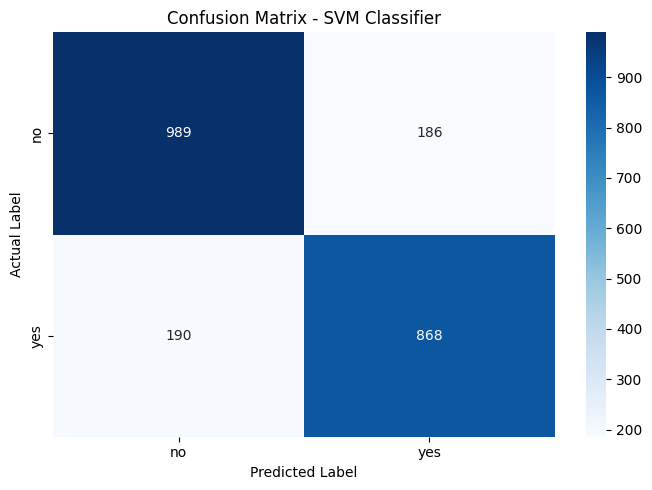

Accuracy: 0.8316166592028661
Precision: 0.8235294117647058
Recall: 0.8204158790170132
F1 Score: 0.821969696969697


In [ ]:


import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Upload Dataset
uploaded = files.upload()
file_name = next(iter(uploaded))

# 2. Load Dataset
df = pd.read_csv(file_name)
print("Dataset Loaded Successfully!")

# 3. Separate Features and Target
X = df.drop("deposit", axis=1)
y = df["deposit"]

# Convert categorical data into numeric data
X = pd.get_dummies(X, drop_first=True)

# Encode target labels
encoder = LabelEncoder()
y = encoder.fit_transform(y)

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 5. Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 6. Train SVM Classifier
svm = SVC(kernel="linear", C=1)
svm.fit(X_train, y_train)

# 7. Prediction
y_pred = svm.predict(X_test)

# 8. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# 9. Draw Confusion Matrix Diagram
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title("Confusion Matrix - SVM Classifier")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# 10. Calculate Performance Metrics
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:",
      precision_score(y_test, y_pred, zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred, zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred, zero_division=0))